/tmp/ipython-input-3448935992.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(market_ticker + ' ' + ' '.join(stock_tickers), start=start_date, end=end_date)['Close']
[*********************100%***********************]  6 of 6 completed


Sharpe Ratio: -1.17
Total Return: nan%


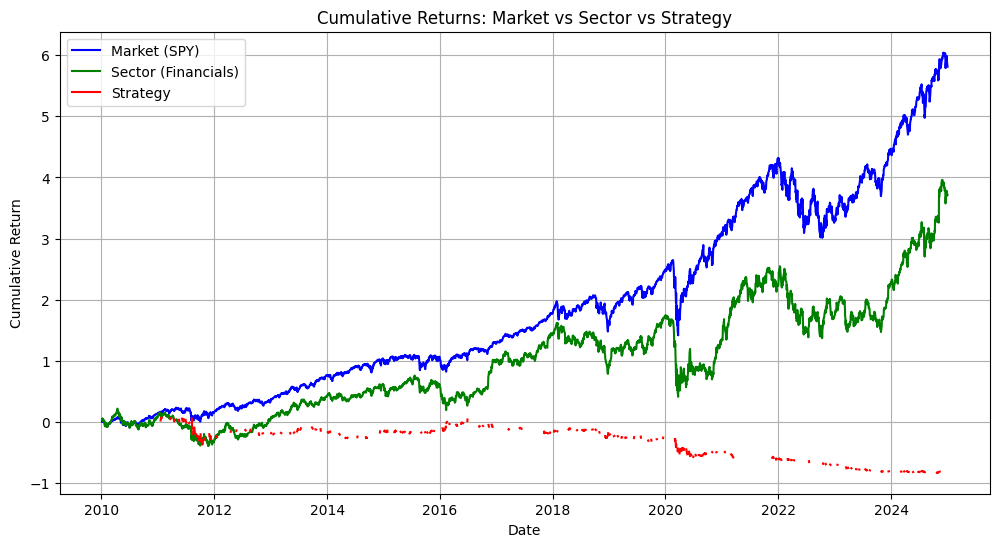

In [23]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import yfinance as yf
import matplotlib.pyplot as plt

# Parameters
market_ticker = 'SPY'
stock_tickers = ['JPM', 'BAC', 'WFC', 'C', 'GS']
start_date = '2010-01-01'
end_date = '2025-01-01'
lookback = 252  # 1 year of trading days for regression
threshold = 1.0  # Z-score threshold for over/under valuation

# Download data
data = yf.download(market_ticker + ' ' + ' '.join(stock_tickers), start=start_date, end=end_date)['Close']
data = data.pct_change().dropna()
sector_index = data[stock_tickers].mean(axis=1)
data['Custom_Sector'] = sector_index

def run_regression(x, y):
    model = LinearRegression()
    x = x.values.reshape(-1, 1)
    y = y.values
    model.fit(x, y)
    predicted = model.predict(x)
    residuals = y - predicted
    return model.coef_[0], model.intercept_, residuals

def backtest_strategy(data, lookback, threshold):
    signals = pd.DataFrame(index=data.index, columns=stock_tickers)
    returns = pd.DataFrame(index=data.index, columns=stock_tickers)

    for t in range(lookback, len(data)):
        # Sector vs Market regression
        market_data = data[market_ticker].iloc[t-lookback:t]
        sector_data = data['Custom_Sector'].iloc[t-lookback:t]
        _, _, sector_residuals = run_regression(market_data, sector_data)

        # Calculate z-score of sector residuals
        sector_z_score = (sector_residuals[-1] - sector_residuals.mean()) / sector_residuals.std()

        # Determine sector valuation
        if sector_z_score > threshold:
            # Sector overvalued, short the strongest stock
            stock_residuals = {}
            for stock in stock_tickers:
                stock_data = data[stock].iloc[t-lookback:t]
                _, _, residuals = run_regression(sector_data, stock_data)
                stock_residuals[stock] = residuals[-1]
            # Short the stock with highest positive residual (most overvalued)
            short_stock = max(stock_residuals, key=stock_residuals.get)
            signals.loc[data.index[t], short_stock] = -1
        elif sector_z_score < -threshold:
            # Sector undervalued, long the strongest stock
            stock_residuals = {}
            for stock in stock_tickers:
                stock_data = data[stock].iloc[t-lookback:t]
                _, _, residuals = run_regression(sector_data, stock_data)
                stock_residuals[stock] = residuals[-1]
            # Long the stock with highest positive residual (most undervalued relative to sector)
            long_stock = max(stock_residuals, key=stock_residuals.get)
            signals.loc[data.index[t], long_stock] = 1

    # Calculate strategy returns
    for stock in stock_tickers:
        returns[stock] = signals[stock].shift(1) * data[stock]

    # Total portfolio return (equal-weighted across positions)
    portfolio_returns = returns.mean(axis=1)
    cumulative_returns = (1 + portfolio_returns).cumprod() - 1

    # Calculate cumulative returns for market and sector
    market_cumulative = (1 + data[market_ticker]).cumprod() - 1
    sector_cumulative = (1 + data['Custom_Sector']).cumprod() - 1

    return signals, returns, portfolio_returns, cumulative_returns, market_cumulative, sector_cumulative

# Run backtest
signals, returns, portfolio_returns, cumulative_returns, market_cumulative, sector_cumulative = backtest_strategy(data, lookback, threshold)

# Basic performance metrics
sharpe_ratio = portfolio_returns.mean() / portfolio_returns.std() * np.sqrt(252)
total_return = cumulative_returns.iloc[-1]
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Total Return: {total_return:.2%}")

# Save results to CSV
signals.to_csv('signals.csv')
returns.to_csv('returns.csv')
cumulative_returns.to_csv('cumulative_returns.csv')

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(market_cumulative.index, market_cumulative, label='Market (SPY)', color='blue')
plt.plot(sector_cumulative.index, sector_cumulative, label='Sector (Financials)', color='green')
plt.plot(cumulative_returns.index, cumulative_returns, label='Strategy', color='red')
plt.title('Cumulative Returns: Market vs Sector vs Strategy')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
